# SCU35 Ethernet crypto: program, test and compare
This notebook uses the **Ethernet IPI design**: MicroBlaze V, 128 KiB local BRAM, AXI Ethernet Lite, AXI Timer and PMC Bridge. It sends actual host payloads over the physical Ethernet link.

Configure the parent lab config.json, connect the RJ45 cable, and set the host adapter to 192.168.10.1/24 (board 192.168.10.2). Select the lab Python environment. Close other UART terminals and restore/stop any running dashboard first.

**LIVE=True programs the Ethernet PDI, captures UART, runs packet tests and benchmarks, then restores the configured recovery PDI.** No separate manual programming or ELF download is needed. LIVE=False freshly verifies the saved capture and measures Python, without touching the board. No flash/eFUSE writes. The AES key 00..1f is public diagnostic data, not a provisioned secure channel.

**Saved execution:** 2026-10-26T04:00:25.894868+00:00. Fresh physical-Ethernet packet tests, Python timings, volatile programming and verified recovery. Executed with LIVE=True; the portable default is restored to False for the next run.

In [1]:
from pathlib import Path
import sys, json, hashlib, time, statistics, os
import pandas as pd
import matplotlib.pyplot as plt
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
HERE = next((p for base in [Path.cwd(), *Path.cwd().parents]
             for p in (base,base/'ethernet',base/'scu35/ethernet') if (p/'launch.py').is_file()),None)
assert HERE is not None, 'Open this notebook inside the repository'
sys.path.insert(0,str(HERE));sys.path.insert(0,str(HERE.parent))
from lab import config
from launch import test
from verify_capture import verify
c=config()
print('Python:',sys.executable)


Python: C:\aiup\pubvenv\Scripts\python.exe


In [2]:
LIVE = False
COUNT = 50  # Per operation/size; nine timed groups = 450 exchanges
if LIVE:
    SESSION = test(c=c,count=COUNT)
    CAPTURE = SESSION/'ethernet/results.json'
    meta=json.loads((SESSION/'session.json').read_text())
    assert meta['hardware_pass'] and meta['recovery_pass'],meta
    print('FRESH PHYSICAL ETHERNET + RECOVERY PASS:',SESSION)
else:
    SESSION=None
    CAPTURE=HERE/'evidence/run3/ethernet/results.json'
    print('RECORDED PHYSICAL ETHERNET; freshly verifying captured bytes:',CAPTURE)
verification=verify(CAPTURE)
report=json.loads(CAPTURE.read_text())
assert report['overall']=='PASS'
print('Functional checks:',len(report['checks']))
display(pd.DataFrame(report['checks'].items(),columns=['check','result']))


Programming Ethernet PDI, testing payloads, then verifying recovery.


Evidence: C:\aiup\s35p2\ethernet_runs\test_20261025_215934_057402


 


E35_START,1,128KiB,100MHz


E35_CRYPTO_INIT,0


...

CMP_NEG,AES-GCM,2048,64


CMP_VECTOR,LMS-SHAKE256,56,4460,56,86D711535677C7E522831339E3FF8DE400A83B87C50749FFE42A9EFA3C832D5F


ETH_HARDWARE_AND_RECOVERY_PASS C:\aiup\s35p2\ethernet_runs\test_20261025_215934_057402


FRESH PHYSICAL ETHERNET + RECOVERY PASS: C:\aiup\s35p2\ethernet_runs\test_20261025_215934_057402
OFFLINE_ETHERNET_CAPTURE_PASS: 20 exact payload/hash cases; bad-tag and replay response records; unique response nonces
Functional checks: 24


,check,result
0,plain_16,PASS
1,encrypt_16,PASS
2,authenticated_echo_16,PASS
3,SHA3-256_16,PASS
4,SHAKE-256_16,PASS
5,plain_64,PASS
6,encrypt_64,PASS
7,authenticated_echo_64,PASS
8,SHA3-256_64,PASS
9,SHAKE-256_64,PASS


## Physical-link benchmarks
Host RTT measures UDP send-to-receive, including the network and device. Host request encryption and response verification are outside RTT. Sequential payload MB/s is not saturated link bandwidth or isolated AES throughput. Separate rows show the transport baseline, encrypted response and authenticated decrypt/encrypt echo.

,method,payload_bytes,packets,median_rtt_us,p95_rtt_us,sequential_payload_MBps
0,UDP plaintext echo,64,50,332.10,450.6,0.165609
1,UDP plaintext echo,256,50,465.70,1081.8,0.487391
2,UDP plaintext echo,1024,50,1030.15,3171.4,0.705901
3,PMC encrypt response,64,50,429.60,1261.0,0.114682
4,PMC encrypt response,256,50,547.10,668.1,0.386417
5,PMC encrypt response,1024,50,1079.40,1621.5,0.877292
6,PMC decrypt + encrypt echo,64,50,493.70,1018.3,0.101613
7,PMC decrypt + encrypt echo,256,50,622.70,1204.0,0.370329
8,PMC decrypt + encrypt echo,1024,50,1153.40,5547.2,0.600863


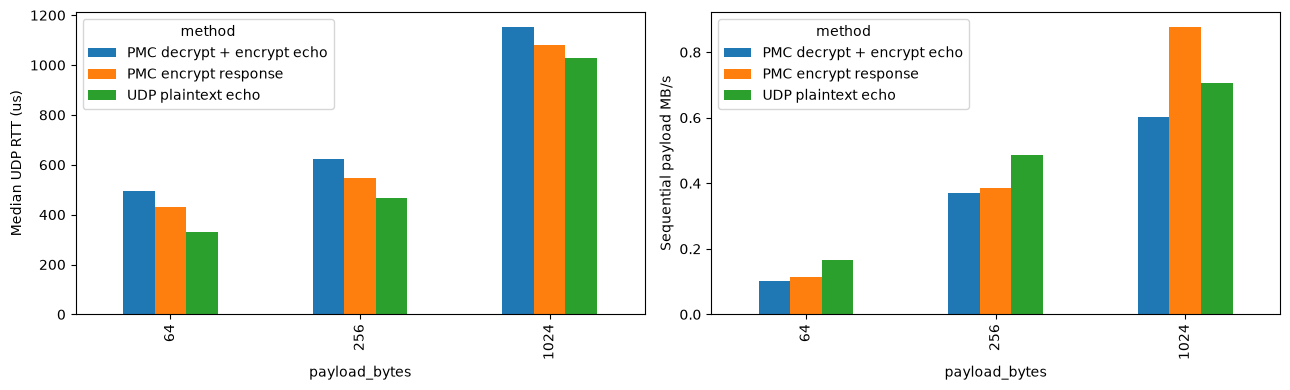

In [3]:
network=pd.DataFrame(report['benchmarks'])
display(network)
fig,axes=plt.subplots(1,2,figsize=(13,4))
network.pivot(index='payload_bytes',columns='method',values='median_rtt_us').plot.bar(ax=axes[0])
axes[0].set_ylabel('Median UDP RTT (us)')
network.pivot(index='payload_bytes',columns='method',values='sequential_payload_MBps').plot.bar(ax=axes[1])
axes[1].set_ylabel('Sequential payload MB/s')
fig.tight_layout();display(fig);plt.close(fig)


## Fresh Python crypto timing
These host-only library timings exclude network, device and transport costs. They are intentionally separate from the UDP RTT table. Exact captured SHA/AES responses, changed-tag rejection and replay records were verified above. Fresh AES encryptions below use unique nonces.

In [4]:
aes=AESGCM(bytes(range(32)));host_rows=[]
for size in [16,64,256,1024]:
    payload=bytes((i*17+size)%256 for i in range(size))
    prefix=os.urandom(8)
    for method in ['SHA3-256','SHAKE-256','AES-GCM-ENC','AES-GCM-DEC']:
        iv=os.urandom(12);ct=aes.encrypt(iv,payload,None);samples=[]
        for iteration in range(500):
            nonce=prefix+iteration.to_bytes(4,'big')
            started=time.perf_counter_ns()
            if method=='SHA3-256':value=hashlib.sha3_256(payload).digest()
            elif method=='SHAKE-256':value=hashlib.shake_256(payload).digest(32)
            elif method=='AES-GCM-ENC':value=aes.encrypt(nonce,payload,None)
            else:value=aes.decrypt(iv,ct,None)
            samples.append((time.perf_counter_ns()-started)/1000)
        if method=='AES-GCM-DEC':assert value==payload
        host_rows.append({'method':method,'payload_bytes':size,'Python median us':statistics.median(samples),
                          'Python mean us':statistics.mean(samples),'samples':len(samples)})
display(pd.DataFrame(host_rows))
if SESSION:
    (SESSION/'python_timings.json').write_text(json.dumps(host_rows,indent=2))


,method,payload_bytes,Python median us,Python mean us,samples
0,SHA3-256,16,1.7,1.7844,500
1,SHAKE-256,16,1.8,1.7734,500
2,AES-GCM-ENC,16,1.4,1.3870,500
3,AES-GCM-DEC,16,1.4,1.4158,500
4,SHA3-256,64,1.5,1.5114,500
5,SHAKE-256,64,1.5,1.6178,500
6,AES-GCM-ENC,64,1.4,1.4392,500
7,AES-GCM-DEC,64,1.4,1.4396,500
8,SHA3-256,256,1.8,1.7894,500
9,SHAKE-256,256,1.8,1.9590,500


## Start the live HTML dashboard
From the lab directory, using the same Python environment/config:
```text
python ethernet/launch.py dashboard
```
The launcher programs the Ethernet image and retains its board reservation while running. Open the printed localhost URL. Buttons select plain UDP, AES-GCM, SHA3 and SHAKE; payload sizes, pause/resume, and tamper/replay tests update the real traffic and plots.

Use **Restore board & stop traffic** when finished. Do not run this notebook's LIVE cell while the dashboard owns the board. The dashboard's highlighted LMS/HSS panels display recorded native-PMC verification results; full post-quantum verification is not implemented by this Ethernet firmware. The SHAKE building-block button is live.

GitHub Pages hosts the lesson and screenshots; the live dashboard runs locally with the connected SCU35.